# Análise Exploratória — PeNSE 2019 e 2024

## Contexto do projeto

Este projeto investiga a relação entre o uso de tecnologias digitais e indicadores de saúde emocional em crianças e adolescentes.

O projeto parte da hipótese de que características relacionadas ao uso de tecnologia — como tempo de exposição às telas, uso de redes sociais, jogos, uso noturno, experiências negativas em ambientes digitais e outros padrões de utilização — podem apresentar associação com indicadores de ansiedade e sofrimento emocional.

## Pergunta de pesquisa

Existe associação entre o uso de tecnologias digitais e indicadores de ansiedade ou sofrimento emocional entre crianças e adolescentes?

Como perguntas complementares, buscamos investigar:

- O tempo de uso de tecnologias digitais apresenta associação com indicadores de saúde emocional?
- Diferentes formas de uso da tecnologia apresentam associações diferentes com esses indicadores?
- Experiências negativas em ambientes digitais podem estar relacionadas a piores indicadores de saúde emocional?
- Existem diferenças de acordo com idade, sexo ou outras características dos estudantes?

## Objetivo desta análise exploratória

Realizar uma análise exploratória dos microdados da Pesquisa Nacional de Saúde do Escolar (PeNSE), inicialmente considerando as edições de 2019 e 2024, para identificar variáveis que possam contribuir para a investigação da relação entre tecnologia e saúde emocional entre estudantes brasileiros.

A análise buscará identificar principalmente:

1. Variáveis relacionadas ao acesso e uso de tecnologias digitais;
2. Variáveis relacionadas a redes sociais, internet, celular e outros dispositivos;
3. Variáveis relacionadas a experiências negativas no ambiente digital;
4. Possíveis indicadores de saúde emocional, como preocupação, tristeza, solidão, sono ou outros sintomas disponíveis na pesquisa;
5. Possíveis associações entre esses grupos de variáveis.

## Limitação metodológica

A revisão inicial dos questionários da PeNSE mostrou que a pesquisa não possui uma variável que meça diretamente o desenvolvimento de ansiedade causado pelo uso de tecnologia.

Portanto, os dados da PeNSE não permitem afirmar que o uso de tecnologia causa ansiedade.

A análise será utilizada para investigar possíveis associações entre variáveis relacionadas ao uso de tecnologia e indicadores de saúde emocional disponíveis na base.

Os resultados deverão ser interpretados como associações estatísticas e não como relações de causa e efeito.

In [1]:
import pandas as pd

In [2]:
df_2024 = pd.read_excel("PENSE2024_MICRODADOS.xlsx")

FileNotFoundError: [Errno 2] No such file or directory: 'PENSE2024_MICRODADOS.xlsx'

In [3]:
import os

os.listdir()

['.gitkeep', '01_eda_pense_2019_2024.ipynb']

In [4]:
import os

print("Pasta atual:")
print(os.getcwd())

print("\nPastas um nível acima:")
print(os.listdir(".."))

print("\nConteúdo da pasta data:")
print(os.listdir("../data"))

Pasta atual:
c:\Users\zarai\Downloads\Ansiosamente-conectados\notebooks

Pastas um nível acima:
['.git', '.gitignore', 'data', 'docs', 'notebooks', 'README.md', 'reports', 'scripts', 'src']

Conteúdo da pasta data:
['interim', 'processed', 'raw']


In [5]:
import os

print("Conteúdo de data/raw:")
print(os.listdir("../data/raw"))

Conteúdo de data/raw:
['.gitkeep', 'pense_2019', 'pense_2024']


In [6]:
import os

print("=== PeNSE 2019 ===")
print(os.listdir("../data/raw/pense_2019"))

print("\n=== PeNSE 2024 ===")
print(os.listdir("../data/raw/pense_2024"))

=== PeNSE 2019 ===
['Dados']

=== PeNSE 2024 ===
['Documentacao']


In [7]:
import os

for raiz, pastas, arquivos in os.walk("../data/raw"):
    print("\n📁", raiz)
    
    for pasta in pastas:
        print("   📂", pasta)
        
    for arquivo in arquivos:
        print("   📄", arquivo)


📁 ../data/raw
   📂 pense_2019
   📂 pense_2024
   📄 .gitkeep

📁 ../data/raw\pense_2019
   📂 Dados

📁 ../data/raw\pense_2019\Dados
   📂 Dados

📁 ../data/raw\pense_2019\Dados\Dados
   📂 CSV
   📂 Documentacao
   📂 SAS
   📂 XLSX

📁 ../data/raw\pense_2019\Dados\Dados\CSV
   📄 PENSE2019_MICRODADOS.csv

📁 ../data/raw\pense_2019\Dados\Dados\Documentacao
   📂 Documentacao

📁 ../data/raw\pense_2019\Dados\Dados\Documentacao\Documentacao
   📂 Exemplos_Calculo_R_SAS
   📄 Dicionario_PENSE2019_Microdados.xls

📁 ../data/raw\pense_2019\Dados\Dados\Documentacao\Documentacao\Exemplos_Calculo_R_SAS
   📄 Exemplo_R.txt
   📄 Exemplo_SAS.txt

📁 ../data/raw\pense_2019\Dados\Dados\SAS
   📄 pense2019_microdados.sas7bdat

📁 ../data/raw\pense_2019\Dados\Dados\XLSX
   📄 PENSE2019_MICRODADOS.xlsx

📁 ../data/raw\pense_2024
   📂 Documentacao

📁 ../data/raw\pense_2024\Documentacao
   📂 Dados
   📂 Exemplos_Calculo_R_SAS
   📄 Dicionário Microdados PeNSE2024.xlsx

📁 ../data/raw\pense_2024\Documentacao\Dados
   📂 CSV
   📂 

In [8]:
import os

for raiz, pastas, arquivos in os.walk("../data/raw"):
    for arquivo in arquivos:
        if arquivo.lower().endswith((".csv", ".xlsx")):
            print(os.path.join(raiz, arquivo))

../data/raw\pense_2019\Dados\Dados\CSV\PENSE2019_MICRODADOS.csv
../data/raw\pense_2019\Dados\Dados\XLSX\PENSE2019_MICRODADOS.xlsx
../data/raw\pense_2024\Documentacao\Dicionário Microdados PeNSE2024.xlsx
../data/raw\pense_2024\Documentacao\Dados\CSV\PENSE2024_MICRODADOS.csv
../data/raw\pense_2024\Documentacao\Dados\XLSX\PENSE2024_MICRODADOS.xlsx


In [9]:
import pandas as pd

caminho_2019 = "../data/raw/pense_2019/Dados/Dados/CSV/PENSE2019_MICRODADOS.csv"
caminho_2024 = "../data/raw/pense_2024/Documentacao/Dados/CSV/PENSE2024_MICRODADOS.csv"

df_2019 = pd.read_csv(caminho_2019, sep=";", low_memory=False)
df_2024 = pd.read_csv(caminho_2024, sep=";", low_memory=False)

print("PeNSE 2019:", df_2019.shape)
print("PeNSE 2024:", df_2024.shape)

PeNSE 2019: (165838, 1)
PeNSE 2024: (153870, 1)


In [10]:
with open(caminho_2019, "r", encoding="utf-8-sig") as arquivo:
    print("2019:")
    print(arquivo.readline()[:1000])

with open(caminho_2024, "r", encoding="utf-8-sig") as arquivo:
    print("\n2024:")
    print(arquivo.readline()[:1000])

2019:
REGIAO,UF,MUNICIPIO_CAP,TIPO_MUNIC,SITUACAO,DEP_ADMIN,ESFERA,ESCOLA,TURMA,ALUNO,ANO_TURMA,B00004,B01001A,B01003,B01004,B01005,B01002,B01021A,B01026A1,B01026A2,B01006,B01007,B01010A,B01014,B01015B,B01016,B01017,B01018A,B01019A,B01020A,B01008B,B02019A,B02017A,B02018B,B02028,B02029,B02030,B02031,B02032,B02033,B02034,B02035,B02036,B02037,B02038,B02039,B02040,B02001,B02004B,B02010A,B02011,B02013,B02023A,B02021A,B02020B,B02041,B02042,B03001A1,B03002A1,B03001A2,B03002A2,B03003A,B03005B,B03006B,B03007A,B03009B,B03010B,B04001,B04002A,B04003,B04009A,B04010,B04012,B04013,B04014,B04015,B04011A01,B04011A02,B04011A03,B04011A04,B04011A05,B04011A06,B04006B,B04005A,B04016,B05002A,B05003A,B05007,B05009,B05004A,B05005A,B05006B,B05011,B05010A,B06001,B06002A,B06003B,B06004A,B06005A,B06006A,B07001,B07002,B07004,B07006,B07007A,B07008,B07011,B07012,B07013,B07009,B12003,B12004,B12005,B12006,B12007,B12008,B08001,B08002,B08011A,B08006A,B08014,B08007,B08012A,B08015,B08016,B08013A,B08008A,B08009A,B08010A,B10

In [11]:
import pandas as pd

df_2019 = pd.read_csv(caminho_2019, sep=",", low_memory=False)
df_2024 = pd.read_csv(caminho_2024, sep=",", low_memory=False)

print("PeNSE 2019:", df_2019.shape)
print("PeNSE 2024:", df_2024.shape)

PeNSE 2019: (165838, 306)
PeNSE 2024: (153870, 430)


In [12]:
palavras = [
    "internet", "celular", "computador", "telefone",
    "tela", "rede", "social", "ansiedade",
    "ansioso", "preocupado", "sono", "dormir",
    "triste", "sozinho", "saude_mental"
]

print("=== POSSÍVEIS VARIÁVEIS - 2019 ===")
for coluna in df_2019.columns:
    if any(palavra in coluna.lower() for palavra in palavras):
        print(coluna)

print("\n=== POSSÍVEIS VARIÁVEIS - 2024 ===")
for coluna in df_2024.columns:
    if any(palavra in coluna.lower() for palavra in palavras):
        print(coluna)

=== POSSÍVEIS VARIÁVEIS - 2019 ===

=== POSSÍVEIS VARIÁVEIS - 2024 ===


In [14]:
import pandas as pd

caminho_dicionario_2024 = "../data/raw/pense_2024/Documentacao/Dicionário Microdados PeNSE2024.xlsx"

excel = pd.ExcelFile(caminho_dicionario_2024)

print("Abas do dicionário:")
print(excel.sheet_names)

Abas do dicionário:
['PeNSE2024']


In [15]:
dicionario_2024 = pd.read_excel(
    caminho_dicionario_2024,
    sheet_name="PeNSE2024"
)

print("Tamanho do dicionário:", dicionario_2024.shape)

print("\nColunas:")
print(dicionario_2024.columns.tolist())

display(dicionario_2024.head(10))

Tamanho do dicionário: (433, 6)

Colunas:
['Tipo', 'Tamanho', 'Nome da Variável', 'Descrição da Variável', 'Categoria', 'Observações']


,Tipo,Tamanho,Nome da Variável,Descrição da Variável,Categoria,Observações
0,Num,8.0,REGIAO,código de regiões,1 - norte\n2 - nordeste\n3 - sudeste\n4 - sul\...,NaN
1,Num,8.0,UF,código UF,NaN,NaN
2,Num,8.0,CAPITAL,indica se é município da capital,1 - é capital\n0 - não é capital,NaN
3,Num,8.0,PESO_INICIAL,NaN,NaN,usa no procmeans
4,Num,8.0,IND_EXPANSAO,NaN,NaN,tem que manter na base ind_expansao = 0
5,Num,8.0,PESO_ALUNO_FREQ,peso final,NaN,NaN
6,Char,27.0,POSEST,NaN,NaN,NaN
7,Num,8.0,TOTAIS_POSEST,totais posest,NaN,NaN
8,Char,4.0,ESTRATO_EXP,estrato,NaN,forma chave única
9,Num,8.0,ESCOLA,UPA,NaN,forma chave única


In [16]:
palavras_chave = [
    "internet",
    "celular",
    "computador",
    "telefone",
    "rede social",
    "redes sociais",
    "jogos",
    "ansiedade",
    "ansioso",
    "preocupado",
    "preocupação",
    "sono",
    "dormir",
    "triste",
    "tristeza",
    "sozinho",
    "solidão",
    "saúde mental"
]

texto = dicionario_2024[
    ["Descrição da Variável", "Categoria", "Observações"]
].fillna("").astype(str).agg(" ".join, axis=1).str.lower()

resultado_2024 = dicionario_2024[
    texto.apply(
        lambda x: any(palavra in x for palavra in palavras_chave)
    )
]

display(
    resultado_2024[
        ["Nome da Variável", "Descrição da Variável", "Categoria"]
    ]
)

,Nome da Variável,Descrição da Variável,Categoria
22,B01010A,"CONTANDO COM VOCÊ, quantas pessoas moram na su...",1 - 1 pessoa (moro sozinho)\n2 - 2 pessoas\n3 ...
23,B01014,Você tem celular?,1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...
24,B01015B,Na sua casa tem computador ou notebook?,1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...
25,B01016,Você tem acesso à internet em sua casa?,1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...
33,B02018B,"Nas suas refeições, com que frequência você co...",1 - Todos os dias da semana\n2 - 5 a 6 dias po...
75,B03010C,Quantas horas por dia você costuma ficar senta...,1 - Até 1 hora por dia\n2 - Mais de 1 hora até...
79,B04009B,"NOS ÚLTIMOS 30 DIAS, na maioria das vezes, com...","1 - Comprei numa loja, bar, botequim, padaria ..."
133,B07013,"NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a...",1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...
146,B07016,"NOS ÚLTIMOS 30 DIAS, você ameaçou, ofendeu ou ...",1 - Sim\n2 - Não\n-2 - Abandono\n-9 - Sem resp...
148,B12004,"NOS ÚLTIMOS 30 DIAS, com que frequência você s...",1 - Nunca\n2 - Raramente\n3 - Às vezes\n4 - Na...


In [17]:
pd.set_option("display.max_colwidth", None)

for _, linha in resultado_2024.iterrows():
    print("=" * 80)
    print("VARIÁVEL:", linha["Nome da Variável"])
    print("DESCRIÇÃO:", linha["Descrição da Variável"])
    print("CATEGORIA:", linha["Categoria"])

VARIÁVEL: B01010A
DESCRIÇÃO: CONTANDO COM VOCÊ, quantas pessoas moram na sua casa ou apartamento?
CATEGORIA: 1 - 1 pessoa (moro sozinho)
2 - 2 pessoas
3 - 3 pessoas
4 - 4 pessoas
5 - 5 pessoas
6 - 6 pessoas
7 - 7 pessoas
8 - 8 pessoas
9 - 9 pessoas
10 - 10 pessoas ou mais
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B01014
DESCRIÇÃO: Você tem celular?
CATEGORIA: 1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B01015B
DESCRIÇÃO: Na sua casa tem computador ou notebook?
CATEGORIA: 1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B01016
DESCRIÇÃO: Você tem acesso à internet em sua casa?
CATEGORIA: 1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B02018B
DESCRIÇÃO: Nas suas refeições, com que frequência você costuma comer fazendo alguma outra coisa (assistindo à TV, mexendo no computador ou no celular)?
CATEGORIA: 1 - Todos os dias da semana
2 - 5 a 6 dias por semana
3 - 3 a 4 dias por semana
4 - 1 a 2 dias por semana
5 - Não costumo comer fazendo alguma outra coisa

In [18]:
termos_tecnologia = [
    "celular", "internet", "computador", "notebook",
    "rede social", "redes sociais", "jogo", "videogame",
    "horas por dia"
]

termos_emocionais = [
    "preocup", "ansied", "ansioso",
    "triste", "sozinho", "solid",
    "dormir", "sono", "nervoso",
    "irritado", "saúde mental"
]

for _, linha in dicionario_2024.iterrows():
    descricao = str(linha["Descrição da Variável"]).lower()

    if any(termo in descricao for termo in termos_tecnologia + termos_emocionais):
        print("=" * 70)
        print("VARIÁVEL:", linha["Nome da Variável"])
        print("DESCRIÇÃO:", linha["Descrição da Variável"])

VARIÁVEL: B01014
DESCRIÇÃO: Você tem celular?
VARIÁVEL: B01015B
DESCRIÇÃO: Na sua casa tem computador ou notebook?
VARIÁVEL: B01016
DESCRIÇÃO: Você tem acesso à internet em sua casa?
VARIÁVEL: B02018B
DESCRIÇÃO: Nas suas refeições, com que frequência você costuma comer fazendo alguma outra coisa (assistindo à TV, mexendo no computador ou no celular)?
VARIÁVEL: B03009C
DESCRIÇÃO: Quantas horas por dia você assiste a filmes, séries, novelas e outros programas de plataformas digitais de vídeo na televisão (TV)? (NÃO contar sábado, domingo e feriado)
VARIÁVEL: B03010C
DESCRIÇÃO: Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)
VARIÁVEL: B07004
DESCRIÇÃO: NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável entendeu suas preocupações e problemas?
VARIÁVEL: B07013
DESCRIÇÃO: NOS ÚLTIMOS 30 D

In [19]:
termos_foco = [
    "celular",
    "computador",
    "notebook",
    "internet",
    "redes sociais",
    "rede social",
    "assistindo a tv",
    "assistindo televisão",
    "filmes",
    "séries",
    "videogame",
    "ameaçado",
    "ofendido",
    "humilhado",
    "triste",
    "sozinho",
    "preocupado",
    "dormir",
    "sono"
]

descricao = (
    dicionario_2024["Descrição da Variável"]
    .fillna("")
    .astype(str)
    .str.lower()
)

selecao_2024 = dicionario_2024[
    descricao.apply(lambda x: any(t in x for t in termos_foco))
][["Nome da Variável", "Descrição da Variável"]]

print("Quantidade encontrada:", len(selecao_2024))

for _, linha in selecao_2024.iterrows():
    print(
        linha["Nome da Variável"],
        "->",
        linha["Descrição da Variável"]
    )

Quantidade encontrada: 17
B01014 -> Você tem celular?
B01015B -> Na sua casa tem computador ou notebook?
B01016 -> Você tem acesso à internet em sua casa?
B02018B -> Nas suas refeições, com que frequência você costuma comer fazendo alguma outra coisa (assistindo à TV, mexendo no computador ou no celular)?
B03009C -> Quantas horas por dia você assiste a filmes, séries, novelas e outros programas de plataformas digitais de vídeo na televisão (TV)? (NÃO contar sábado, domingo e feriado)
B03010C -> Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)
B07007B -> NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola o esculachou, zoou, mangou, intimidou ou caçoou tanto que você ficou magoado, incomodado, aborrecido, ofendido ou humilhado?
B07013 -> NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a),

In [20]:
variaveis_foco = [
    "B01014",
    "B01015B",
    "B01016",
    "B03009C",
    "B03010C",
    "B07013",
    "B07016",
    "B12004",
    "B12005"
]

foco_2024 = dicionario_2024[
    dicionario_2024["Nome da Variável"].isin(variaveis_foco)
]

for _, linha in foco_2024.iterrows():
    print("=" * 80)
    print("VARIÁVEL:", linha["Nome da Variável"])
    print("DESCRIÇÃO:", linha["Descrição da Variável"])
    print("CATEGORIAS:")
    print(linha["Categoria"])

VARIÁVEL: B01014
DESCRIÇÃO: Você tem celular?
CATEGORIAS:
1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B01015B
DESCRIÇÃO: Na sua casa tem computador ou notebook?
CATEGORIAS:
1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B01016
DESCRIÇÃO: Você tem acesso à internet em sua casa?
CATEGORIAS:
1 - Sim
2 - Não
-2 - Abandono
-9 - Sem resposta
VARIÁVEL: B03009C
DESCRIÇÃO: Quantas horas por dia você assiste a filmes, séries, novelas e outros programas de plataformas digitais de vídeo na televisão (TV)? (NÃO contar sábado, domingo e feriado)
CATEGORIAS:
1 - Não assisto a televisão (TV)
2 - Até 1 hora por dia
3 - Mais de 1 hora até 2 horas por dia
4 - Mais de 2 horas até 3 horas por dia
5 - Mais de 3 horas até 4 horas por dia
6 - Mais de 4 horas até 5 horas por dia
7 - Mais de 5 horas até 6 horas por dia
8 - Mais de 6 horas até 7 horas por dia
9 - Mais de 7 horas até 8 horas por dia
10 - Mais de 8 horas por dia
11 - Não sei / não lembro
-2 - Abandono
-9 - Sem resposta
VAR

In [21]:
variaveis_foco = [
    "B01014",
    "B01015B",
    "B01016",
    "B03009C",
    "B03010C",
    "B07013",
    "B07016",
    "B12004",
    "B12005"
]

for var in variaveis_foco:
    print("=" * 60)
    print("VARIÁVEL:", var)
    
    if var in df_2024.columns:
        print(df_2024[var].value_counts(dropna=False).sort_index())
    else:
        print("Variável não encontrada nos microdados.")

VARIÁVEL: B01014
B01014
-9.0        35
-2.0        28
 1.0    137804
 2.0     10869
 NaN      5134
Name: count, dtype: int64
VARIÁVEL: B01015B
B01015B
-9.0       66
-2.0       29
 1.0    94098
 2.0    54543
 NaN     5134
Name: count, dtype: int64
VARIÁVEL: B01016
B01016
-9.0        45
-2.0        29
 1.0    144660
 2.0      4002
 NaN      5134
Name: count, dtype: int64
VARIÁVEL: B03009C
B03009C
-9.0       301
-2.0       124
 1.0     24107
 2.0     27831
 3.0     26011
 4.0     18886
 5.0     12183
 6.0      7882
 7.0      5567
 8.0      3124
 9.0      2478
 10.0     6708
 11.0    13534
 NaN      5134
Name: count, dtype: int64
VARIÁVEL: B03010C
B03010C
-9.0       461
-2.0       130
 1.0     21399
 2.0     20229
 3.0     20709
 4.0     18390
 5.0     14615
 6.0     11363
 7.0      7539
 8.0      5737
 9.0     13122
 10.0    15042
 NaN      5134
Name: count, dtype: int64
VARIÁVEL: B07013
B07013
-9.0       395
-2.0       262
 1.0     18419
 2.0    129660
 NaN      5134
Name: count, dtype: 

In [22]:
variaveis_analise = {
    "B03009C": "Horas por dia em plataformas digitais",
    "B03010C": "Horas sentado em atividades como TV, videogame e computador",
    "B07013": "Sofreu ameaça/ofensa/humilhação nas redes sociais",
    "B12004": "Frequência com que se sentiu muito preocupado(a)",
    "B12005": "Frequência com que se sentiu triste"
}

for codigo, descricao in variaveis_analise.items():
    print("\n" + "=" * 70)
    print(codigo, "-", descricao)
    print("=" * 70)

    if codigo in df_2024.columns:
        print(df_2024[codigo].value_counts(dropna=False).sort_index())
    else:
        print("Variável não encontrada.")


B03009C - Horas por dia em plataformas digitais
B03009C
-9.0       301
-2.0       124
 1.0     24107
 2.0     27831
 3.0     26011
 4.0     18886
 5.0     12183
 6.0      7882
 7.0      5567
 8.0      3124
 9.0      2478
 10.0     6708
 11.0    13534
 NaN      5134
Name: count, dtype: int64

B03010C - Horas sentado em atividades como TV, videogame e computador
B03010C
-9.0       461
-2.0       130
 1.0     21399
 2.0     20229
 3.0     20709
 4.0     18390
 5.0     14615
 6.0     11363
 7.0      7539
 8.0      5737
 9.0     13122
 10.0    15042
 NaN      5134
Name: count, dtype: int64

B07013 - Sofreu ameaça/ofensa/humilhação nas redes sociais
B07013
-9.0       395
-2.0       262
 1.0     18419
 2.0    129660
 NaN      5134
Name: count, dtype: int64

B12004 - Frequência com que se sentiu muito preocupado(a)
B12004
-9.0      543
-2.0      318
 1.0    13972
 2.0    17440
 3.0    37878
 4.0    41244
 5.0    37341
 NaN     5134
Name: count, dtype: int64

B12005 - Frequência com que se sen

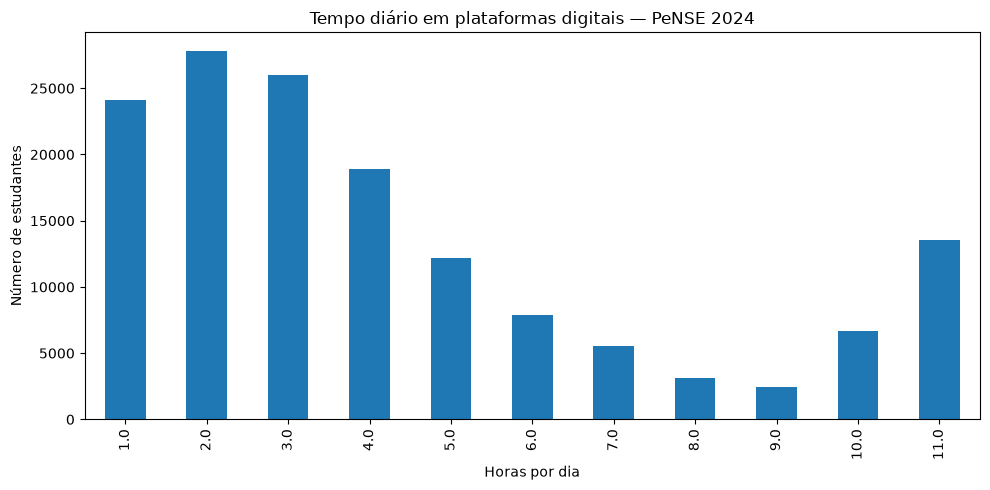

In [23]:
import matplotlib.pyplot as plt

dados = df_2024["B03009C"].dropna()

# retirar códigos negativos, como abandono/sem resposta
dados = dados[dados >= 0]

contagem = dados.value_counts().sort_index()

plt.figure(figsize=(10,5))
contagem.plot(kind="bar")

plt.title("Tempo diário em plataformas digitais — PeNSE 2024")
plt.xlabel("Horas por dia")
plt.ylabel("Número de estudantes")

plt.tight_layout()
plt.show()

Tempo em plataformas digitais × frequência de preocupação


B12004,1.0,2.0,3.0,4.0,5.0
B03009C,,,,,
1.0,13.19,11.75,23.08,24.92,27.05
2.0,10.26,12.01,25.27,26.85,25.61
3.0,6.85,11.58,27.49,29.86,24.23
4.0,6.76,11.27,27.17,30.34,24.47
5.0,6.48,11.68,26.67,30.43,24.75
6.0,7.19,11.03,26.59,30.22,24.97
7.0,7.13,11.93,25.68,29.18,26.09
8.0,7.51,11.55,25.64,30.04,25.26
9.0,10.53,10.98,25.77,27.43,25.28


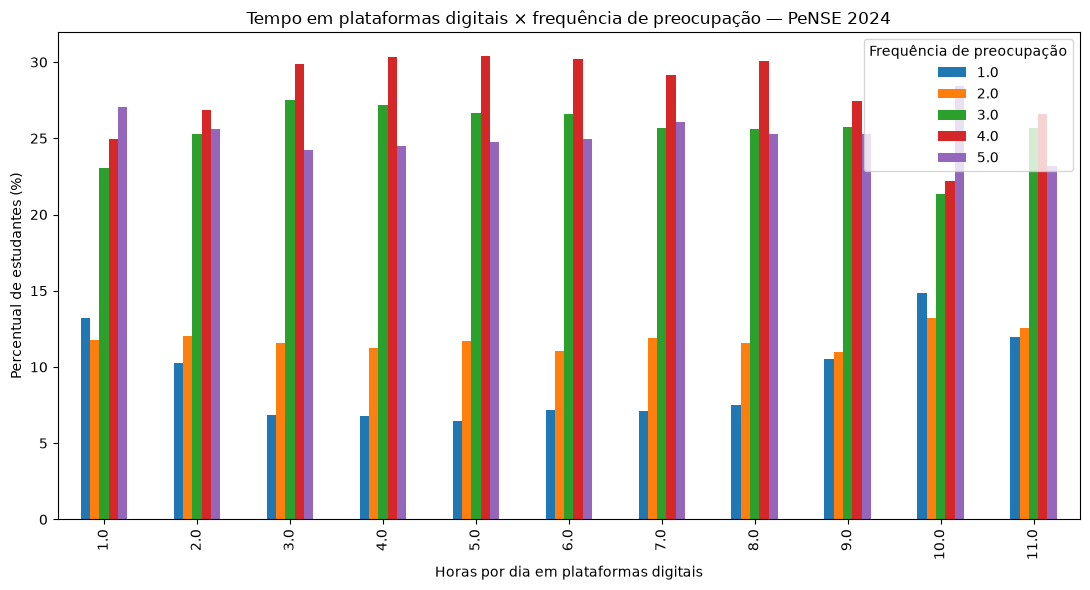

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Selecionar apenas as duas variáveis
analise = df_2024[["B03009C", "B12004"]].copy()

# Remover valores ausentes e códigos negativos
analise = analise.dropna()
analise = analise[
    (analise["B03009C"] >= 0) &
    (analise["B12004"] >= 0)
]

# Criar tabela cruzada em porcentagem
cruzamento = pd.crosstab(
    analise["B03009C"],
    analise["B12004"],
    normalize="index"
) * 100

print("Tempo em plataformas digitais × frequência de preocupação")
display(cruzamento.round(2))

# Gráfico
cruzamento.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Tempo em plataformas digitais × frequência de preocupação — PeNSE 2024")
plt.xlabel("Horas por dia em plataformas digitais")
plt.ylabel("Percentual de estudantes (%)")
plt.legend(title="Frequência de preocupação")
plt.tight_layout()
plt.show()

## Conclusão preliminar

A análise exploratória da PeNSE 2024 identificou variáveis relacionadas ao acesso e ao uso de tecnologias digitais, como posse de celular, acesso à internet e tempo diário em plataformas digitais.

Também foram identificadas variáveis relacionadas ao bem-estar emocional dos estudantes, como frequência de preocupação e tristeza, além de experiências negativas em redes sociais.

A análise cruzada entre o tempo diário em plataformas digitais e a frequência de preocupação mostra diferenças na distribuição das respostas entre as categorias de uso. Esses resultados permitem explorar uma possível associação entre uso de tecnologias digitais e indicadores de bem-estar emocional.

Entretanto, os resultados não permitem afirmar que o uso de tecnologia causa ansiedade. A PeNSE não utiliza, nessas variáveis, uma escala clínica específica de diagnóstico de ansiedade. Portanto, os resultados devem ser interpretados como associações exploratórias.

### Limitação metodológica

A análise utiliza indicadores disponíveis na PeNSE como aproximações para o tema da ansiedade. Em etapas futuras, o projeto poderá complementar esses dados com instrumentos validados especificamente para avaliação de sintomas de ansiedade em crianças e adolescentes. 